#### Notebook 07 — Scalability and Operator Implementation

This notebook will take the work from Notebooks 01–06 a step further: moving from exploratory analysis in individual notebooks towards a reusable, configurable and scalable MNO analytics pipeline.

The main objective is to demonstrate how the analytical methods could be packaged for implementation across different MNO data environments, where operators may use different schemas, database systems, timestamp conventions and data volumes.

In [17]:
# 1 — Imports and configuration

from pathlib import Path
from datetime import datetime, timezone
import json
import sqlite3
import time
import platform
import sys
import warnings

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
NOTEBOOK07_DIR = PROCESSED_DIR / "notebook_07"
REPORTS_DIR = PROJECT_ROOT / "reports"

NOTEBOOK07_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

INPUT_FILE = RAW_DIR / "MPD_sample_synthetic_ken_3000subs_full.csv"

DATABASE_FILE = NOTEBOOK07_DIR / "operator_processing.sqlite"

CHUNK_SIZE = 100_000

GRID_SIZE = 0.05

MIN_SUBSCRIBERS_PER_ZONE = 5

RANDOM_STATE = 42

print("Project root:", PROJECT_ROOT)
print("Input file:", INPUT_FILE)
print("Output directory:", NOTEBOOK07_DIR)
print("Chunk size:", CHUNK_SIZE)

Project root: /Users/Apple/Documents/mno_mobility_intelligence_residence_and_population_displacement_inference
Input file: /Users/Apple/Documents/mno_mobility_intelligence_residence_and_population_displacement_inference/data/raw/MPD_sample_synthetic_ken_3000subs_full.csv
Output directory: /Users/Apple/Documents/mno_mobility_intelligence_residence_and_population_displacement_inference/data/processed/notebook_07
Chunk size: 100000


In [18]:
# 2 — Inspect the input dataset

if not INPUT_FILE.exists():
    raise FileNotFoundError(
        f"Dataset not found: {INPUT_FILE}\n"
        "Place the full synthetic MNO dataset inside data/raw/."
    )

file_size_mb = INPUT_FILE.stat().st_size / (1024 ** 2)

print(f"File size: {file_size_mb:.2f} MB")

header = pd.read_csv(INPUT_FILE, 
                         dtype={
                             "msisdn": "string",
                             "cell_id": "string",
                             "latitude": "float64",
                             "longitude": "float64",
                             "data_type": "category",
                             "service": "category",
                             "location_target": "category",
                             "location_place": "category",
                             "profile": "category",
                             "record_profile": "category",
                             "movement_profile": "category"
                         },
                         nrows=5,
                         low_memory=False
                     )

# convert the datetime column to datetime
header["datetime"] = pd.to_datetime(
    header["datetime"],
    errors="coerce"
)

# Convert synthetic Boolean labels safely.
def convert_to_boolean(series):
    mapped = (
        series.astype("string")
        .str.strip()
        .str.lower()
        .map({
            "1": True,
            "0": False,
            "true": True,
            "false": False,
            "yes": True,
            "no": False
        })
    )

    return mapped.astype("boolean")


header["tourist"] = convert_to_boolean(header["tourist"])
header["is_robot"] = convert_to_boolean(header["is_robot"])

print("\nDataset columns:")
print(header.columns.tolist())

print("\nSample records:")
display(header.head())

print("\nData types:")
print(header.dtypes)

File size: 133.47 MB

Dataset columns:
['msisdn', 'datetime', 'cell_id', 'latitude', 'longitude', 'data_type', 'service', 'location_target', 'location_place', 'movement_dist', 'movement_speed', 'is_robot', 'profile', 'tourist', 'record_profile', 'movement_profile']

Sample records:


,msisdn,datetime,cell_id,latitude,longitude,data_type,service,location_target,location_place,movement_dist,movement_speed,is_robot,profile,tourist,record_profile,movement_profile
0,subscribers_00323,2026-02-01 01:23:00,33597,-1.2674,36.9147,CDR,2G,home,home,0.000000,0.000000,False,neutral,False,very_high,short
1,subscribers_00323,2026-02-01 03:55:00,33597,-1.2674,36.9147,CDR,2G,home,home,0.000000,0.000000,False,neutral,False,very_high,short
2,subscribers_00323,2026-02-01 06:53:00,33597,-1.2674,36.9147,CDR,2G,home,home,0.000000,0.000000,False,neutral,False,very_high,short
3,subscribers_00323,2026-02-01 07:52:00,33597,-1.2674,36.9147,CDR,2G,home,home,0.000000,0.000000,False,neutral,False,very_high,short
4,subscribers_00323,2026-02-01 09:07:00,31239,-1.2712,36.8996,CDR,2G,other,other,1.727961,0.383991,False,neutral,False,very_high,short



Data types:
msisdn                      string
datetime            datetime64[us]
cell_id                     string
latitude                   float64
longitude                  float64
data_type                 category
service                   category
location_target           category
location_place            category
movement_dist              float64
movement_speed             float64
is_robot                   boolean
profile                   category
tourist                    boolean
record_profile            category
movement_profile          category
dtype: object


#### 3 — Define a configurable MNO schema adapter

Different operators may provide different field names for equivalent information.

For example, one operator may use subscriber_id, another may use msisdn, and another may use hashed_subscriber_id.

Rather than rewriting the analytical pipeline for every operator, this cell standardises incoming field names into a canonical schema.

In [19]:
# CELL 3: CONFIGURABLE MNO SCHEMA ADAPTER

CANONICAL_SCHEMA = {
    "subscriber_id": "msisdn",
    "event_timestamp": "datetime",
    "cell_identifier": "cell_id",
    "latitude": "latitude",
    "longitude": "longitude",
    "record_type": "data_type",
    "service_type": "service"
}

# Mapping for the current synthetic dataset.
# Dictionary keys are incoming source column names.
CURRENT_OPERATOR_MAPPING = {
    "msisdn": "msisdn",
    "datetime": "datetime",
    "cell_id": "cell_id",
    "latitude": "latitude",
    "longitude": "longitude",
    "data_type": "data_type",
    "service": "service"
}

REQUIRED_COLUMNS = [
    "msisdn",
    "datetime",
    "cell_id",
    "latitude",
    "longitude"
]

OPTIONAL_COLUMNS = [
    "data_type",
    "service"
]


def standardise_operator_schema(
    dataframe,
    column_mapping,
    required_columns=REQUIRED_COLUMNS
):
    """
    Convert an operator-specific schema into the canonical MNO schema.
    """

    df = dataframe.copy()

    missing_source_columns = [
        source
        for source in column_mapping
        if source not in df.columns
    ]

    if missing_source_columns:
        raise ValueError(
            f"Source columns missing: {missing_source_columns}"
        )

    df = df.rename(columns=column_mapping)

    missing_required = [
        col for col in required_columns
        if col not in df.columns
    ]

    if missing_required:
        raise ValueError(
            f"Required canonical columns missing: {missing_required}"
        )

    return df


standardised_sample = standardise_operator_schema(
    header,
    CURRENT_OPERATOR_MAPPING
)

print("Schema standardisation successful.")
print(standardised_sample.columns.tolist())

Schema standardisation successful.
['msisdn', 'datetime', 'cell_id', 'latitude', 'longitude', 'data_type', 'service', 'location_target', 'location_place', 'movement_dist', 'movement_speed', 'is_robot', 'profile', 'tourist', 'record_profile', 'movement_profile']


#### 4 — Test the schema adapter with a different operator

This simulates receiving records from another MNO with different column names.

In [20]:
# CELL 4: TEST ALTERNATIVE OPERATOR SCHEMA

alternative_operator_data = pd.DataFrame({
    "subscriber_id": ["SUB001", "SUB002"],
    "event_timestamp": [
        "2026-02-01 21:30:00",
        "2026-02-02 22:15:00"
    ],
    "cell_identifier": ["CELL001", "CELL002"],
    "latitude": [-1.2864, -1.2921],
    "longitude": [36.8172, 36.8219],
    "record_type": ["CDR", "IPDR"],
    "service_type": ["Voice", "Data"]
})

ALTERNATIVE_OPERATOR_MAPPING = {
    "subscriber_id": "msisdn",
    "event_timestamp": "datetime",
    "cell_identifier": "cell_id",
    "latitude": "latitude",
    "longitude": "longitude",
    "record_type": "data_type",
    "service_type": "service"
}

alternative_standardised = standardise_operator_schema(
    alternative_operator_data,
    ALTERNATIVE_OPERATOR_MAPPING
)

display(alternative_standardised)

,msisdn,datetime,cell_id,latitude,longitude,data_type,service
0,SUB001,2026-02-01 21:30:00,CELL001,-1.2864,36.8172,CDR,Voice
1,SUB002,2026-02-02 22:15:00,CELL002,-1.2921,36.8219,IPDR,Data


#### 5 — Define reusable data quality validation
The pipeline should validate incoming data before generating analytical features.

This includes:
- Required fields.
- Missing subscriber identifiers.
- Invalid timestamps.
- Invalid coordinates.
- Duplicate records.
- Invalid latitude and longitude ranges.

In [21]:
# CELL 5: REUSABLE DATA QUALITY VALIDATION

def validate_mno_data(dataframe):
    """
    Validate canonical MNO event records.

    Returns:
        cleaned_dataframe
        quality_report
    """

    df = dataframe.copy()

    initial_rows = len(df)

    required = [
        "msisdn",
        "datetime",
        "cell_id",
        "latitude",
        "longitude"
    ]

    missing_columns = [
        col for col in required
        if col not in df.columns
    ]

    if missing_columns:
        raise ValueError(
            f"Missing required columns: {missing_columns}"
        )

    missing_before = df[required].isna().sum()

    df["datetime"] = pd.to_datetime(
        df["datetime"],
        errors="coerce",
        utc=True
    )

    df["latitude"] = pd.to_numeric(
        df["latitude"],
        errors="coerce"
    )

    df["longitude"] = pd.to_numeric(
        df["longitude"],
        errors="coerce"
    )

    invalid_timestamp = df["datetime"].isna()

    invalid_coordinates = (
        df["latitude"].isna()
        | df["longitude"].isna()
        | ~df["latitude"].between(-90, 90)
        | ~df["longitude"].between(-180, 180)
    )

    missing_identifier = (
        df["msisdn"].isna()
        | df["cell_id"].isna()
    )

    duplicate_mask = df.duplicated(
        subset=[
            "msisdn",
            "datetime",
            "cell_id",
            "data_type"
        ] if "data_type" in df.columns
        else [
            "msisdn",
            "datetime",
            "cell_id"
        ]
    )

    invalid_rows = (
        invalid_timestamp
        | invalid_coordinates
        | missing_identifier
        | duplicate_mask
    )

    cleaned = df.loc[~invalid_rows].copy()

    quality_report = {
        "input_rows": int(initial_rows),
        "missing_values_by_column": {
            key: int(value)
            for key, value in missing_before.items()
        },
        "invalid_timestamps": int(invalid_timestamp.sum()),
        "invalid_coordinates": int(invalid_coordinates.sum()),
        "missing_identifiers": int(missing_identifier.sum()),
        "duplicate_records": int(duplicate_mask.sum()),
        "removed_rows": int(invalid_rows.sum()),
        "valid_rows": int(len(cleaned)),
        "retention_rate": (
            round(len(cleaned) / initial_rows, 4)
            if initial_rows else 0
        )
    }

    return cleaned, quality_report


sample_cleaned, sample_quality = validate_mno_data(header)

print(json.dumps(sample_quality, indent=4))

{
    "input_rows": 5,
    "missing_values_by_column": {
        "msisdn": 0,
        "datetime": 0,
        "cell_id": 0,
        "latitude": 0,
        "longitude": 0
    },
    "invalid_timestamps": 0,
    "invalid_coordinates": 0,
    "missing_identifiers": 0,
    "duplicate_records": 0,
    "removed_rows": 0,
    "valid_rows": 5,
    "retention_rate": 1.0
}


#### 6 — Define reusable geographic aggregation
For this implementation, the geographic grid is based on rounded latitude and longitude.

The grid is an analytical aggregation unit, not an administrative boundary.

In [22]:
# CELL 6: GEOGRAPHIC GRID ASSIGNMENT

def assign_geographic_grid(
    dataframe,
    grid_size=GRID_SIZE
):
    """
    Assign each event to a geographic grid cell.

    Coordinates are rounded to the configured grid resolution.
    """

    df = dataframe.copy()

    df["grid_latitude"] = (
        np.floor(df["latitude"] / grid_size + 0.5)
        * grid_size
    )

    df["grid_longitude"] = (
        np.floor(df["longitude"] / grid_size + 0.5)
        * grid_size
    )

    df["geographic_zone"] = (
        df["grid_latitude"].round(4).astype(str)
        + "_"
        + df["grid_longitude"].round(4).astype(str)
    )

    return df


grid_sample = assign_geographic_grid(sample_cleaned)

display(
    grid_sample[
        [
            "latitude",
            "longitude",
            "grid_latitude",
            "grid_longitude",
            "geographic_zone"
        ]
    ].head()
)

,latitude,longitude,grid_latitude,grid_longitude,geographic_zone
0,-1.2674,36.9147,-1.25,36.9,-1.25_36.9
1,-1.2674,36.9147,-1.25,36.9,-1.25_36.9
2,-1.2674,36.9147,-1.25,36.9,-1.25_36.9
3,-1.2674,36.9147,-1.25,36.9,-1.25_36.9
4,-1.2712,36.8996,-1.25,36.9,-1.25_36.9


#### 7 — Define the processing pipeline

This function applies schema standardisation, data quality validation, timestamp preparation and geographic aggregation.

In [23]:
# CELL 7: REUSABLE MNO PROCESSING PIPELINE

def process_mno_batch(
    dataframe,
    column_mapping,
    grid_size=GRID_SIZE
):
    """
    Process one batch of MNO events.

    Returns:
        cleaned_data
        quality_report
    """

    standardised = standardise_operator_schema(
        dataframe,
        column_mapping
    )

    cleaned, quality_report = validate_mno_data(
        standardised
    )

    cleaned = assign_geographic_grid(
        cleaned,
        grid_size=grid_size
    )

    cleaned["event_date"] = (
        cleaned["datetime"].dt.date.astype(str)
    )

    cleaned["event_hour"] = (
        cleaned["datetime"].dt.hour
    )

    cleaned["is_nighttime"] = (
        (cleaned["event_hour"] >= 20)
        | (cleaned["event_hour"] < 6)
    )

    cleaned["is_weekend"] = (
        cleaned["datetime"].dt.dayofweek >= 5
    )

    return cleaned, quality_report


processed_sample, sample_report = process_mno_batch(
    header,
    CURRENT_OPERATOR_MAPPING
)

display(processed_sample.head())

,msisdn,datetime,cell_id,latitude,longitude,data_type,service,location_target,location_place,movement_dist,...,tourist,record_profile,movement_profile,grid_latitude,grid_longitude,geographic_zone,event_date,event_hour,is_nighttime,is_weekend
0,subscribers_00323,2026-02-01 01:23:00+00:00,33597,-1.2674,36.9147,CDR,2G,home,home,0.000000,...,False,very_high,short,-1.25,36.9,-1.25_36.9,2026-02-01,1,True,True
1,subscribers_00323,2026-02-01 03:55:00+00:00,33597,-1.2674,36.9147,CDR,2G,home,home,0.000000,...,False,very_high,short,-1.25,36.9,-1.25_36.9,2026-02-01,3,True,True
2,subscribers_00323,2026-02-01 06:53:00+00:00,33597,-1.2674,36.9147,CDR,2G,home,home,0.000000,...,False,very_high,short,-1.25,36.9,-1.25_36.9,2026-02-01,6,False,True
3,subscribers_00323,2026-02-01 07:52:00+00:00,33597,-1.2674,36.9147,CDR,2G,home,home,0.000000,...,False,very_high,short,-1.25,36.9,-1.25_36.9,2026-02-01,7,False,True
4,subscribers_00323,2026-02-01 09:07:00+00:00,31239,-1.2712,36.8996,CDR,2G,other,other,1.727961,...,False,very_high,short,-1.25,36.9,-1.25_36.9,2026-02-01,9,False,True


#### 8 — Prepare the scalable processing database
Instead of retaining every processed event in memory, use SQLite to incrementally store aggregated results.

This is a lightweight demonstration of a disk-backed processing approach. For larger operator deployments, the same design could be implemented using a data warehouse, distributed SQL engine or Spark.

In [24]:
# CELL 8: INITIALISE DISK-BACKED PROCESSING DATABASE

if DATABASE_FILE.exists():
    DATABASE_FILE.unlink()

conn = sqlite3.connect(DATABASE_FILE)

cursor = conn.cursor()

cursor.executescript("""
CREATE TABLE zone_events (
    geographic_zone TEXT PRIMARY KEY,
    total_events INTEGER DEFAULT 0,
    nighttime_events INTEGER DEFAULT 0,
    daytime_events INTEGER DEFAULT 0,
    weekend_events INTEGER DEFAULT 0
);

CREATE TABLE subscriber_zone (
    msisdn TEXT NOT NULL,
    geographic_zone TEXT NOT NULL,
    event_count INTEGER DEFAULT 0,
    PRIMARY KEY (msisdn, geographic_zone)
);

CREATE TABLE subscriber_zone_day (
    msisdn TEXT NOT NULL,
    geographic_zone TEXT NOT NULL,
    event_date TEXT NOT NULL,
    PRIMARY KEY (msisdn, geographic_zone, event_date)
);

CREATE TABLE zone_cell (
    geographic_zone TEXT NOT NULL,
    cell_id TEXT NOT NULL,
    PRIMARY KEY (geographic_zone, cell_id)
);

CREATE TABLE zone_active_day (
    geographic_zone TEXT NOT NULL,
    event_date TEXT NOT NULL,
    PRIMARY KEY (geographic_zone, event_date)
);
""")

conn.commit()

print("SQLite processing database initialised.")

SQLite processing database initialised.


#### 9 — Implement chunk-based ingestion and aggregation

It reads the source CSV in configurable chunks, validates each batch, assigns geographic zones and updates aggregate tables without loading the entire dataset into memory.

In [25]:
# CELL 9: CHUNK-BASED MNO PROCESSING

def process_large_mno_file(
    input_file,
    connection,
    column_mapping,
    chunk_size=CHUNK_SIZE,
    grid_size=GRID_SIZE
):
    """
    Incrementally process an MNO CSV using disk-backed aggregates.

    Only aggregate outputs are retained in SQLite.
    """

    start_time = time.perf_counter()

    total_rows = 0
    valid_rows = 0
    total_invalid_rows = 0
    total_chunks = 0

    quality_reports = []

    reader = pd.read_csv(
        input_file,
        chunksize=chunk_size,
        low_memory=False
    )

    for chunk_number, raw_chunk in enumerate(reader, start=1):

        batch_start = time.perf_counter()

        processed, quality = process_mno_batch(
            raw_chunk,
            column_mapping,
            grid_size=grid_size
        )

        total_rows += quality["input_rows"]
        valid_rows += quality["valid_rows"]
        total_invalid_rows += quality["removed_rows"]
        total_chunks += 1

        quality["chunk_number"] = chunk_number
        quality_reports.append(quality)

        if processed.empty:
            print(f"Chunk {chunk_number}: no valid records")
            continue

        # Aggregate events by geographic zone.
        zone_batch = (
            processed
            .groupby("geographic_zone")
            .agg(
                total_events=("msisdn", "size"),
                nighttime_events=("is_nighttime", "sum"),
                weekend_events=("is_weekend", "sum")
            )
            .reset_index()
        )

        zone_batch["daytime_events"] = (
            zone_batch["total_events"]
            - zone_batch["nighttime_events"]
        )

        connection.executemany(
            """
            INSERT INTO zone_events (
                geographic_zone,
                total_events,
                nighttime_events,
                daytime_events,
                weekend_events
            )
            VALUES (?, ?, ?, ?, ?)
            ON CONFLICT(geographic_zone)
            DO UPDATE SET
                total_events =
                    total_events + excluded.total_events,
                nighttime_events =
                    nighttime_events + excluded.nighttime_events,
                daytime_events =
                    daytime_events + excluded.daytime_events,
                weekend_events =
                    weekend_events + excluded.weekend_events
            """,
            [
                (
                    str(row.geographic_zone),
                    int(row.total_events),
                    int(row.nighttime_events),
                    int(row.daytime_events),
                    int(row.weekend_events)
                )
                for row in zone_batch.itertuples(index=False)
            ]
        )

        # Aggregate subscriber activity by zone.
        subscriber_batch = (
            processed
            .groupby(["msisdn", "geographic_zone"])
            .size()
            .reset_index(name="event_count")
        )

        connection.executemany(
            """
            INSERT INTO subscriber_zone (
                msisdn,
                geographic_zone,
                event_count
            )
            VALUES (?, ?, ?)
            ON CONFLICT(msisdn, geographic_zone)
            DO UPDATE SET
                event_count =
                    event_count + excluded.event_count
            """,
            [
                (
                    str(row.msisdn),
                    str(row.geographic_zone),
                    int(row.event_count)
                )
                for row in subscriber_batch.itertuples(index=False)
            ]
        )

        # Store distinct subscriber-zone-date combinations.
        subscriber_days = (
            processed[
                ["msisdn", "geographic_zone", "event_date"]
            ]
            .drop_duplicates()
        )

        connection.executemany(
            """
            INSERT OR IGNORE INTO subscriber_zone_day (
                msisdn,
                geographic_zone,
                event_date
            )
            VALUES (?, ?, ?)
            """,
            [
                (
                    str(row.msisdn),
                    str(row.geographic_zone),
                    str(row.event_date)
                )
                for row in subscriber_days.itertuples(index=False)
            ]
        )

        # Store unique cell IDs per geographic zone.
        cells = (
            processed[["geographic_zone", "cell_id"]]
            .drop_duplicates()
        )

        connection.executemany(
            """
            INSERT OR IGNORE INTO zone_cell (
                geographic_zone,
                cell_id
            )
            VALUES (?, ?)
            """,
            [
                (
                    str(row.geographic_zone),
                    str(row.cell_id)
                )
                for row in cells.itertuples(index=False)
            ]
        )

        # Store unique active dates per geographic zone.
        active_days = (
            processed[["geographic_zone", "event_date"]]
            .drop_duplicates()
        )

        connection.executemany(
            """
            INSERT OR IGNORE INTO zone_active_day (
                geographic_zone,
                event_date
            )
            VALUES (?, ?)
            """,
            [
                (
                    str(row.geographic_zone),
                    str(row.event_date)
                )
                for row in active_days.itertuples(index=False)
            ]
        )

        connection.commit()

        batch_seconds = time.perf_counter() - batch_start

        print(
            f"Chunk {chunk_number}: "
            f"{len(raw_chunk):,} input records | "
            f"{len(processed):,} valid records | "
            f"{batch_seconds:.2f} seconds"
        )

    elapsed = time.perf_counter() - start_time

    summary = {
        "total_chunks": total_chunks,
        "total_input_rows": total_rows,
        "valid_rows": valid_rows,
        "invalid_rows": total_invalid_rows,
        "retention_rate": (
            valid_rows / total_rows if total_rows else 0
        ),
        "processing_seconds": elapsed,
        "rows_per_second": (
            total_rows / elapsed if elapsed else 0
        )
    }

    return summary, pd.DataFrame(quality_reports)


processing_summary, chunk_quality_report = process_large_mno_file(
    input_file=INPUT_FILE,
    connection=conn,
    column_mapping=CURRENT_OPERATOR_MAPPING,
    chunk_size=CHUNK_SIZE
)

print("\nPROCESSING SUMMARY")
display(pd.DataFrame([processing_summary]))

Chunk 1: 100,000 input records | 100,000 valid records | 0.25 seconds
Chunk 2: 100,000 input records | 100,000 valid records | 0.23 seconds
Chunk 3: 100,000 input records | 100,000 valid records | 0.26 seconds
Chunk 4: 100,000 input records | 100,000 valid records | 0.24 seconds
Chunk 5: 100,000 input records | 100,000 valid records | 0.26 seconds
Chunk 6: 100,000 input records | 100,000 valid records | 0.26 seconds
Chunk 7: 100,000 input records | 100,000 valid records | 0.28 seconds
Chunk 8: 100,000 input records | 100,000 valid records | 0.24 seconds
Chunk 9: 100,000 input records | 100,000 valid records | 0.25 seconds
Chunk 10: 100,000 input records | 100,000 valid records | 0.24 seconds
Chunk 11: 72,608 input records | 72,608 valid records | 0.18 seconds

PROCESSING SUMMARY


,total_chunks,total_input_rows,valid_rows,invalid_rows,retention_rate,processing_seconds,rows_per_second
0,11,1072608,1072608,0,1.0,2.979192,360033.200351


#### 10 — Generate geographic aggregate features
The next step is to retrieve aggregate features from SQLite.

We calculate:
- Unique subscribers per zone.
- Total events.
- Number of active cells.
- Number of active days.
- Nighttime and daytime activity.
- Weekend activity.
- Mean events per subscriber.
- Median events per subscriber.
- Subscriber activity consistency.

In [26]:
# CELL 10: GENERATE GEOGRAPHIC AGGREGATE FEATURES

zone_features = pd.read_sql_query(
    """
    WITH subscriber_stats AS (
        SELECT
            geographic_zone,
            COUNT(*) AS unique_subscribers,
            AVG(event_count) AS mean_events_per_subscriber,
            AVG(
                CASE WHEN event_count > 0
                THEN 1.0 ELSE 0.0 END
            ) AS subscriber_activity_ratio
        FROM subscriber_zone
        GROUP BY geographic_zone
    ),

    subscriber_medians AS (
        SELECT
            geographic_zone,
            event_count
        FROM subscriber_zone
    ),

    cell_stats AS (
        SELECT
            geographic_zone,
            COUNT(*) AS unique_cells
        FROM zone_cell
        GROUP BY geographic_zone
    ),

    day_stats AS (
        SELECT
            geographic_zone,
            COUNT(*) AS active_days
        FROM zone_active_day
        GROUP BY geographic_zone
    ),

    subscriber_day_stats AS (
        SELECT
            geographic_zone,
            COUNT(*) AS subscriber_zone_active_days
        FROM subscriber_zone_day
        GROUP BY geographic_zone
    )

    SELECT
        z.geographic_zone,
        s.unique_subscribers,
        z.total_events,
        c.unique_cells,
        d.active_days,
        z.nighttime_events,
        z.daytime_events,
        z.weekend_events,
        s.mean_events_per_subscriber,
        sd.subscriber_zone_active_days,
        CAST(z.nighttime_events AS REAL)
            / NULLIF(z.total_events, 0)
            AS nighttime_activity_ratio,
        CAST(z.weekend_events AS REAL)
            / NULLIF(z.total_events, 0)
            AS weekend_activity_ratio,
        CAST(z.total_events AS REAL)
            / NULLIF(s.unique_subscribers, 0)
            AS events_per_subscriber,
        CAST(z.total_events AS REAL)
            / NULLIF(c.unique_cells, 0)
            AS events_per_cell

    FROM zone_events z

    LEFT JOIN subscriber_stats s
        ON z.geographic_zone = s.geographic_zone

    LEFT JOIN cell_stats c
        ON z.geographic_zone = c.geographic_zone

    LEFT JOIN day_stats d
        ON z.geographic_zone = d.geographic_zone

    LEFT JOIN subscriber_day_stats sd
        ON z.geographic_zone = sd.geographic_zone
    """,
    conn
)

print("Geographic zones:", len(zone_features))

display(zone_features.head())

Geographic zones: 97


,geographic_zone,unique_subscribers,total_events,unique_cells,active_days,nighttime_events,daytime_events,weekend_events,mean_events_per_subscriber,subscriber_zone_active_days,nighttime_activity_ratio,weekend_activity_ratio,events_per_subscriber,events_per_cell
0,-1.15_36.6,44,60,24,23,10,50,27,1.363636,53,0.166667,0.450000,1.363636,2.500000
1,-1.15_36.65,671,3178,559,28,835,2343,1177,4.736215,1254,0.262744,0.370359,4.736215,5.685152
2,-1.15_36.7,252,391,106,28,47,344,214,1.551587,305,0.120205,0.547315,1.551587,3.688679
3,-1.15_36.75,251,790,130,28,73,717,227,3.147410,335,0.092405,0.287342,3.147410,6.076923
4,-1.15_36.8,293,628,155,28,164,464,284,2.143345,392,0.261146,0.452229,2.143345,4.051613


#### 11 — Add median subscriber activity
SQLite does not provide a built-in portable median aggregate, so calculate this from the subscriber-zone table.

In [27]:
# CELL 11: MEDIAN SUBSCRIBER ACTIVITY

subscriber_activity = pd.read_sql_query(
    """
    SELECT
        geographic_zone,
        event_count
    FROM subscriber_zone
    """,
    conn
)

subscriber_medians = (
    subscriber_activity
    .groupby("geographic_zone")["event_count"]
    .median()
    .rename("median_events_per_subscriber")
    .reset_index()
)

zone_features = zone_features.merge(
    subscriber_medians,
    on="geographic_zone",
    how="left",
    validate="one_to_one"
)

display(zone_features.head())

,geographic_zone,unique_subscribers,total_events,unique_cells,active_days,nighttime_events,daytime_events,weekend_events,mean_events_per_subscriber,subscriber_zone_active_days,nighttime_activity_ratio,weekend_activity_ratio,events_per_subscriber,events_per_cell,median_events_per_subscriber
0,-1.15_36.6,44,60,24,23,10,50,27,1.363636,53,0.166667,0.450000,1.363636,2.500000,1.0
1,-1.15_36.65,671,3178,559,28,835,2343,1177,4.736215,1254,0.262744,0.370359,4.736215,5.685152,1.0
2,-1.15_36.7,252,391,106,28,47,344,214,1.551587,305,0.120205,0.547315,1.551587,3.688679,1.0
3,-1.15_36.75,251,790,130,28,73,717,227,3.147410,335,0.092405,0.287342,3.147410,6.076923,1.0
4,-1.15_36.8,293,628,155,28,164,464,284,2.143345,392,0.261146,0.452229,2.143345,4.051613,1.0


#### 12 — Apply geographic minimum-group suppression
This ensures that the exported aggregate dataset excludes geographic zones with fewer than the configured number of unique subscribers.

In [28]:
# CELL 12: MINIMUM GROUP SIZE SUPPRESSION

suppressed_zones = zone_features[
    zone_features["unique_subscribers"]
    < MIN_SUBSCRIBERS_PER_ZONE
].copy()

publishable_zone_features = zone_features[
    zone_features["unique_subscribers"]
    >= MIN_SUBSCRIBERS_PER_ZONE
].copy()

suppression_summary = {
    "total_zones": int(len(zone_features)),
    "suppressed_zones": int(len(suppressed_zones)),
    "retained_zones": int(len(publishable_zone_features)),
    "minimum_subscribers": MIN_SUBSCRIBERS_PER_ZONE
}

print(json.dumps(suppression_summary, indent=4))

display(publishable_zone_features.head())

{
    "total_zones": 97,
    "suppressed_zones": 10,
    "retained_zones": 87,
    "minimum_subscribers": 5
}


,geographic_zone,unique_subscribers,total_events,unique_cells,active_days,nighttime_events,daytime_events,weekend_events,mean_events_per_subscriber,subscriber_zone_active_days,nighttime_activity_ratio,weekend_activity_ratio,events_per_subscriber,events_per_cell,median_events_per_subscriber
0,-1.15_36.6,44,60,24,23,10,50,27,1.363636,53,0.166667,0.450000,1.363636,2.500000,1.0
1,-1.15_36.65,671,3178,559,28,835,2343,1177,4.736215,1254,0.262744,0.370359,4.736215,5.685152,1.0
2,-1.15_36.7,252,391,106,28,47,344,214,1.551587,305,0.120205,0.547315,1.551587,3.688679,1.0
3,-1.15_36.75,251,790,130,28,73,717,227,3.147410,335,0.092405,0.287342,3.147410,6.076923,1.0
4,-1.15_36.8,293,628,155,28,164,464,284,2.143345,392,0.261146,0.452229,2.143345,4.051613,1.0


#### 13 — Export safe aggregate outputs

In [29]:
# CELL 13: EXPORT AGGREGATED OUTPUTS

ZONE_OUTPUT = (
    NOTEBOOK07_DIR / "operator_geographic_aggregate_features.csv"
)

QUALITY_OUTPUT = (
    NOTEBOOK07_DIR / "operator_chunk_quality_report.csv"
)

SUMMARY_OUTPUT = (
    NOTEBOOK07_DIR / "operator_processing_summary.json"
)

SUPPRESSION_OUTPUT = (
    NOTEBOOK07_DIR / "operator_suppression_summary.json"
)

publishable_zone_features.to_csv(
    ZONE_OUTPUT,
    index=False
)

chunk_quality_report.to_csv(
    QUALITY_OUTPUT,
    index=False
)

with open(SUMMARY_OUTPUT, "w") as f:
    json.dump(processing_summary, f, indent=4)

with open(SUPPRESSION_OUTPUT, "w") as f:
    json.dump(suppression_summary, f, indent=4)

print("Aggregate outputs exported.")

print(ZONE_OUTPUT)
print(QUALITY_OUTPUT)
print(SUMMARY_OUTPUT)

Aggregate outputs exported.
/Users/Apple/Documents/mno_mobility_intelligence_residence_and_population_displacement_inference/data/processed/notebook_07/operator_geographic_aggregate_features.csv
/Users/Apple/Documents/mno_mobility_intelligence_residence_and_population_displacement_inference/data/processed/notebook_07/operator_chunk_quality_report.csv
/Users/Apple/Documents/mno_mobility_intelligence_residence_and_population_displacement_inference/data/processed/notebook_07/operator_processing_summary.json


#### 14 — Evaluate processing performance
Assess the pipeline's processing performance using the actual run.

The key metrics are:
- Total records processed.
- Number of chunks.
- Processing duration.
- Records processed per second.
- Database storage size.
- Valid-record retention rate.

In [31]:
# CELL 14: PROCESSING PERFORMANCE REPORT

database_size_mb = (
    DATABASE_FILE.stat().st_size / (1024 ** 2)
    if DATABASE_FILE.exists()
    else 0
)

performance_report = pd.DataFrame([{
    "total_input_rows": processing_summary["total_input_rows"],
    "valid_rows": processing_summary["valid_rows"],
    "total_chunks": processing_summary["total_chunks"],
    "processing_seconds": round(
        processing_summary["processing_seconds"], 2
    ),
    "rows_per_second": round(
        processing_summary["rows_per_second"], 2
    ),
    "retention_rate": round(
        processing_summary["retention_rate"], 4
    ),
    "database_size_mb": round(database_size_mb, 2),
    "chunk_size": CHUNK_SIZE
}])

display(performance_report)

performance_report.to_csv(
    NOTEBOOK07_DIR / "processing_performance_report.csv",
    index=False
)

,total_input_rows,valid_rows,total_chunks,processing_seconds,rows_per_second,retention_rate,database_size_mb,chunk_size
0,1072608,1072608,11,2.98,360033.2,1.0,30.95,100000


#### 15 — Visualise processing performance

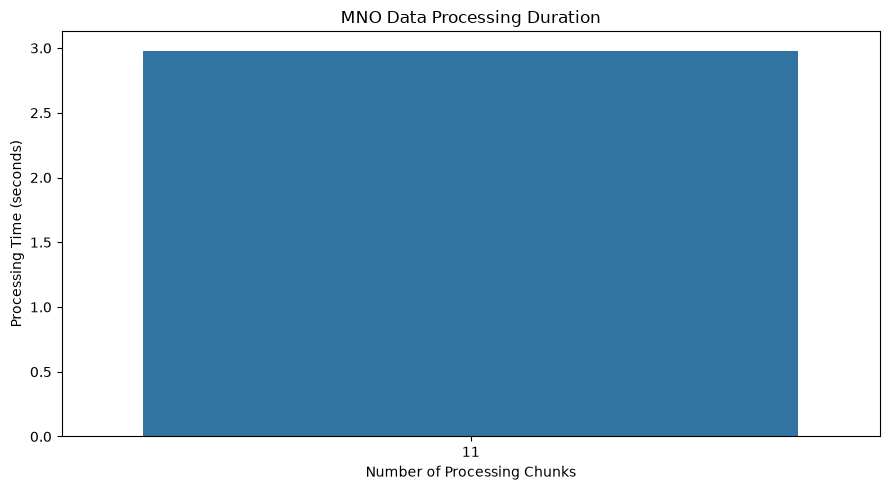

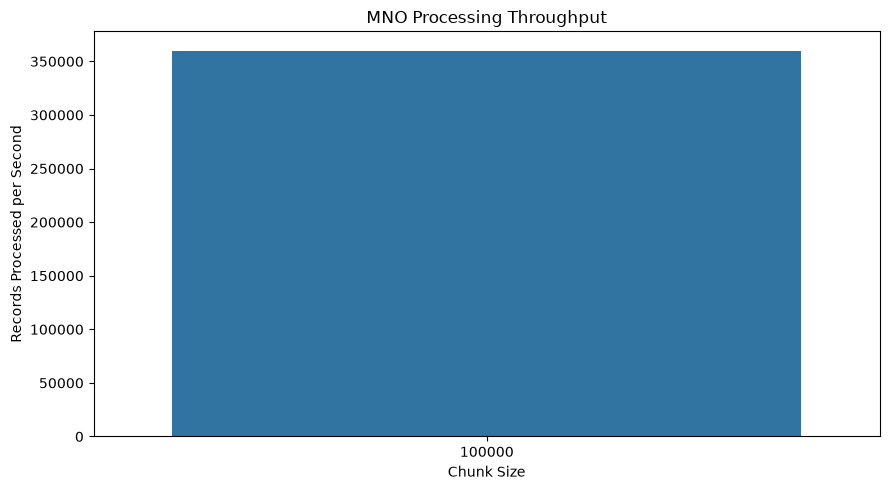

In [32]:
# CELL 15: PROCESSING PERFORMANCE VISUALISATION

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.barplot(
    data=performance_report,
    x="total_chunks",
    y="processing_seconds"
)

plt.title("MNO Data Processing Duration")
plt.xlabel("Number of Processing Chunks")
plt.ylabel("Processing Time (seconds)")

plt.tight_layout()
plt.show()


plt.figure(figsize=(9, 5))

sns.barplot(
    data=performance_report,
    x="chunk_size",
    y="rows_per_second"
)

plt.title("MNO Processing Throughput")
plt.xlabel("Chunk Size")
plt.ylabel("Records Processed per Second")

plt.tight_layout()
plt.show()

#### 16 — Create a reusable SQL implementation
This cell documents how an operator could perform similar geographic aggregation directly within a relational database.

The SQL is written in a PostgreSQL-style format. The exact syntax and timestamp handling may need adaptation for an operator's database platform.

-- CELL 16: SQL IMPLEMENTATION TEMPLATE

-- 1. Create a standardised MNO event table.

`CREATE TABLE standardised_mno_events (
    subscriber_id TEXT,
    event_timestamp TIMESTAMP,
    cell_id TEXT,
    latitude DOUBLE PRECISION,
    longitude DOUBLE PRECISION,
    data_type TEXT,
    service TEXT`
);


-- 2. Create a geographic aggregation table.

`CREATE TABLE geographic_mno_features (
    geographic_zone TEXT,
    unique_subscribers INTEGER,
    total_events BIGINT,
    unique_cells INTEGER,
    active_days INTEGER,
    nighttime_events BIGINT,
    daytime_events BIGINT,
    weekend_events BIGINT,
    nighttime_activity_ratio DOUBLE PRECISION,
    weekend_activity_ratio DOUBLE PRECISION,
    events_per_subscriber DOUBLE PRECISION,
    events_per_cell DOUBLE PRECISION`
);


-- 3. Generate geographic zones.

WITH prepared_events AS (

    SELECT
        subscriber_id,
        event_timestamp,
        cell_id,
        latitude,
        longitude,

        ROUND(latitude / 0.05) * 0.05 AS grid_latitude,

        ROUND(longitude / 0.05) * 0.05 AS grid_longitude,

        CASE
            WHEN EXTRACT(HOUR FROM event_timestamp) >= 20
              OR EXTRACT(HOUR FROM event_timestamp) < 6
            THEN 1
            ELSE 0
        END AS is_nighttime,

        CASE
            WHEN EXTRACT(ISODOW FROM event_timestamp) >= 6
            THEN 1
            ELSE 0
        END AS is_weekend,

        CAST(event_timestamp AS DATE) AS event_date

    FROM standardised_mno_events

    WHERE
        subscriber_id IS NOT NULL
        AND event_timestamp IS NOT NULL
        AND latitude BETWEEN -90 AND 90
        AND longitude BETWEEN -180 AND 180
),

zoned_events AS (

    SELECT
        *,
        CONCAT(
            grid_latitude,
            '_',
            grid_longitude
        ) AS geographic_zone

    FROM prepared_events
),

zone_aggregates AS (

    SELECT
        geographic_zone,

        COUNT(*) AS total_events,

        COUNT(DISTINCT subscriber_id)
            AS unique_subscribers,

        COUNT(DISTINCT cell_id)
            AS unique_cells,

        COUNT(DISTINCT event_date)
            AS active_days,

        SUM(is_nighttime)
            AS nighttime_events,

        SUM(1 - is_nighttime)
            AS daytime_events,

        SUM(is_weekend)
            AS weekend_events

    FROM zoned_events

    GROUP BY geographic_zone

)

SELECT
    *,

    nighttime_events::DOUBLE PRECISION
        / NULLIF(total_events, 0)
        AS nighttime_activity_ratio,

    weekend_events::DOUBLE PRECISION
        / NULLIF(total_events, 0)
        AS weekend_activity_ratio,

    total_events::DOUBLE PRECISION
        / NULLIF(unique_subscribers, 0)
        AS events_per_subscriber,

    total_events::DOUBLE PRECISION
        / NULLIF(unique_cells, 0)
        AS events_per_cell

FROM zone_aggregates

WHERE unique_subscribers >= 5;

#### 17 — Create a reusable operator configuration
Instead of hardcoding assumptions throughout the pipeline, define a configuration file that can be adapted for different operators.

In [33]:
# CELL 17: OPERATOR CONFIGURATION

operator_configuration = {
    "project": "MNO Mobility Intelligence",

    "operator": {
        "operator_name": "Synthetic Kenya MNO",
        "country": "Kenya",
        "data_source": "Synthetic CDR/IPDR dataset"
    },

    "schema": CURRENT_OPERATOR_MAPPING,

    "processing": {
        "chunk_size": CHUNK_SIZE,
        "grid_size_degrees": GRID_SIZE,
        "minimum_subscribers_per_zone": MIN_SUBSCRIBERS_PER_ZONE
    },

    "quality_controls": {
        "require_subscriber_id": True,
        "require_timestamp": True,
        "require_cell_id": True,
        "validate_coordinates": True,
        "remove_duplicate_records": True
    },

    "privacy": {
        "subscriber_level_publication": False,
        "exact_home_coordinates_publication": False,
        "minimum_group_suppression": True
    },

    "execution": {
        "processing_mode": "chunked",
        "storage_engine": "SQLite",
        "random_state": RANDOM_STATE
    }
}

CONFIG_OUTPUT = NOTEBOOK07_DIR / "operator_configuration.json"

with open(CONFIG_OUTPUT, "w") as f:
    json.dump(operator_configuration, f, indent=4)

print("Operator configuration saved:", CONFIG_OUTPUT)

Operator configuration saved: /Users/Apple/Documents/mno_mobility_intelligence_residence_and_population_displacement_inference/data/processed/notebook_07/operator_configuration.json


#### 18 — Implement automated pipeline tests

These tests verify that the main reusable functions behave as expected.

In [34]:
# CELL 18: AUTOMATED FUNCTION TESTS

def test_schema_standardisation():

    sample = pd.DataFrame({
        "subscriber_id": ["A", "B"],
        "event_timestamp": [
            "2026-02-01 20:00:00",
            "2026-02-02 21:00:00"
        ],
        "cell_identifier": ["C1", "C2"],
        "latitude": [-1.2, -1.3],
        "longitude": [36.8, 36.9]
    })

    mapping = {
        "subscriber_id": "msisdn",
        "event_timestamp": "datetime",
        "cell_identifier": "cell_id",
        "latitude": "latitude",
        "longitude": "longitude"
    }

    result = standardise_operator_schema(
        sample,
        mapping
    )

    assert "msisdn" in result.columns
    assert "datetime" in result.columns
    assert "cell_id" in result.columns

    return True


def test_coordinate_validation():

    sample = pd.DataFrame({
        "msisdn": ["A", "B", "C"],
        "datetime": [
            "2026-02-01 20:00:00",
            "2026-02-01 21:00:00",
            "invalid_timestamp"
        ],
        "cell_id": ["C1", "C2", "C3"],
        "latitude": [-1.2, 120, -1.3],
        "longitude": [36.8, 36.9, 36.7]
    })

    cleaned, report = validate_mno_data(sample)

    assert len(cleaned) == 1
    assert report["invalid_timestamps"] == 1
    assert report["invalid_coordinates"] == 1

    return True


def test_geographic_grid_assignment():

    sample = pd.DataFrame({
        "latitude": [-1.2864, -1.2864],
        "longitude": [36.8172, 36.8172]
    })

    result = assign_geographic_grid(sample)

    assert "geographic_zone" in result.columns
    assert result["geographic_zone"].nunique() == 1

    return True


def test_nighttime_classification():

    timestamps = pd.Series(
        pd.to_datetime([
            "2026-02-01 21:00:00",
            "2026-02-02 02:00:00",
            "2026-02-02 12:00:00"
        ], utc=True)
    )

    hours = timestamps.dt.hour

    nighttime = (
        (hours >= 20) | (hours < 6)
    )

    assert nighttime.tolist() == [True, True, False]

    return True


test_results = {
    "schema_standardisation": test_schema_standardisation(),
    "coordinate_validation": test_coordinate_validation(),
    "geographic_grid_assignment": test_geographic_grid_assignment(),
    "nighttime_classification": test_nighttime_classification()
}

display(
    pd.DataFrame(
        [
            {"test": name, "passed": result}
            for name, result in test_results.items()
        ]
    )
)

assert all(test_results.values()), "One or more tests failed."

print("All pipeline tests passed.")

,test,passed
0,schema_standardisation,True
1,coordinate_validation,True
2,geographic_grid_assignment,True
3,nighttime_classification,True


All pipeline tests passed.


#### 19 — Generate a data quality report

This consolidates the chunk-level validation results into an operator-facing summary.

In [35]:
# CELL 19: CONSOLIDATED DATA QUALITY REPORT

if not chunk_quality_report.empty:

    quality_summary = pd.DataFrame([{
        "total_chunks": len(chunk_quality_report),

        "total_input_rows":
            int(chunk_quality_report["input_rows"].sum()),

        "valid_rows":
            int(chunk_quality_report["valid_rows"].sum()),

        "removed_rows":
            int(chunk_quality_report["removed_rows"].sum()),

        "invalid_timestamps":
            int(chunk_quality_report["invalid_timestamps"].sum()),

        "invalid_coordinates":
            int(chunk_quality_report["invalid_coordinates"].sum()),

        "duplicate_records":
            int(chunk_quality_report["duplicate_records"].sum()),

        "missing_identifiers":
            int(chunk_quality_report["missing_identifiers"].sum())
    }])

    quality_summary["retention_rate"] = (
        quality_summary["valid_rows"]
        / quality_summary["total_input_rows"]
    )

    display(quality_summary)

    quality_summary.to_csv(
        NOTEBOOK07_DIR / "operator_data_quality_summary.csv",
        index=False
    )

else:
    print("No quality report available.")

,total_chunks,total_input_rows,valid_rows,removed_rows,invalid_timestamps,invalid_coordinates,duplicate_records,missing_identifiers,retention_rate
0,11,1072608,1072608,0,0,0,0,0,1.0


#### 20 — Generate an operator implementation checklist

In [36]:
# CELL 20: OPERATOR IMPLEMENTATION CHECKLIST

implementation_checklist = [
    {
        "stage": "Data access",
        "task": "Confirm legal basis and data-sharing agreement",
        "status": "Pending"
    },
    {
        "stage": "Data access",
        "task": "Confirm approved data access and transfer mechanism",
        "status": "Pending"
    },
    {
        "stage": "Schema discovery",
        "task": "Obtain operator CDR/IPDR data dictionary",
        "status": "Pending"
    },
    {
        "stage": "Schema discovery",
        "task": "Map operator fields to canonical schema",
        "status": "Demonstrated with synthetic data"
    },
    {
        "stage": "Data quality",
        "task": "Validate identifiers, timestamps and coordinates",
        "status": "Implemented in prototype"
    },
    {
        "stage": "Data quality",
        "task": "Agree on duplicate record handling",
        "status": "Prototype rule defined; operator confirmation required"
    },
    {
        "stage": "Processing",
        "task": "Agree on batch size and processing frequency",
        "status": "Prototype configuration available"
    },
    {
        "stage": "Processing",
        "task": "Benchmark against operator infrastructure",
        "status": "Pending"
    },
    {
        "stage": "Geospatial",
        "task": "Confirm cell tower coordinate reference system",
        "status": "Pending"
    },
    {
        "stage": "Privacy",
        "task": "Complete privacy and data protection assessment",
        "status": "Pending"
    },
    {
        "stage": "Privacy",
        "task": "Agree on aggregation and disclosure controls",
        "status": "Prototype minimum-group suppression implemented"
    },
    {
        "stage": "Validation",
        "task": "Agree on independent validation strategy",
        "status": "Pending"
    },
    {
        "stage": "Deployment",
        "task": "Agree on operator infrastructure and deployment model",
        "status": "Pending"
    },
    {
        "stage": "Handover",
        "task": "Prepare technical documentation and knowledge transfer",
        "status": "Pending"
    }
]

implementation_checklist_df = pd.DataFrame(
    implementation_checklist
)

display(implementation_checklist_df)

implementation_checklist_df.to_csv(
    NOTEBOOK07_DIR / "operator_implementation_checklist.csv",
    index=False
)

,stage,task,status
0,Data access,Confirm legal basis and data-sharing agreement,Pending
1,Data access,Confirm approved data access and transfer mech...,Pending
2,Schema discovery,Obtain operator CDR/IPDR data dictionary,Pending
3,Schema discovery,Map operator fields to canonical schema,Demonstrated with synthetic data
4,Data quality,"Validate identifiers, timestamps and coordinates",Implemented in prototype
5,Data quality,Agree on duplicate record handling,Prototype rule defined; operator confirmation ...
6,Processing,Agree on batch size and processing frequency,Prototype configuration available
7,Processing,Benchmark against operator infrastructure,Pending
8,Geospatial,Confirm cell tower coordinate reference system,Pending
9,Privacy,Complete privacy and data protection assessment,Pending


#### 21 — Create an operator handover summary

In [37]:
# CELL 21: OPERATOR HANDOVER SUMMARY

handover_summary = {
    "project": "MNO Mobility Intelligence",

    "component": "Scalability and Operator Implementation",

    "objective": (
        "Demonstrate a configurable and reusable MNO data processing "
        "workflow suitable for further operator-specific adaptation."
    ),

    "implemented_capabilities": [
        "Configurable MNO schema standardisation",
        "Reusable data quality validation",
        "Timestamp and coordinate validation",
        "Geographic grid assignment",
        "Chunk-based CSV ingestion",
        "Disk-backed aggregation using SQLite",
        "Geographic activity feature generation",
        "Minimum-group suppression",
        "Processing performance reporting",
        "SQL aggregation template",
        "Automated function tests",
        "Operator implementation checklist"
    ],

    "current_data_source": (
        "Synthetic Kenyan CDR/IPDR dataset"
    ),

    "processing_mode": "Chunked CSV ingestion",

    "storage_engine": "SQLite",

    "limitations": [
        "Not tested against real operator infrastructure",
        "No production MNO integration",
        "No operator-specific data dictionary validated",
        "No independent performance benchmark",
        "No production privacy audit",
        "No deployment or operator handover completed"
    ],

    "next_steps": [
        "Validate against an approved real MNO schema",
        "Benchmark alternative processing engines",
        "Develop PySpark or distributed SQL implementation",
        "Introduce automated integration tests",
        "Complete privacy and security review",
        "Prepare deployment and operational documentation"
    ]
}

HANDOVER_OUTPUT = (
    NOTEBOOK07_DIR / "operator_handover_summary.json"
)

with open(HANDOVER_OUTPUT, "w") as f:
    json.dump(handover_summary, f, indent=4)

print(json.dumps(handover_summary, indent=4))

{
    "project": "MNO Mobility Intelligence",
    "component": "Scalability and Operator Implementation",
    "objective": "Demonstrate a configurable and reusable MNO data processing workflow suitable for further operator-specific adaptation.",
    "implemented_capabilities": [
        "Configurable MNO schema standardisation",
        "Reusable data quality validation",
        "Timestamp and coordinate validation",
        "Geographic grid assignment",
        "Chunk-based CSV ingestion",
        "Disk-backed aggregation using SQLite",
        "Geographic activity feature generation",
        "Minimum-group suppression",
        "Processing performance reporting",
        "SQL aggregation template",
        "Automated function tests",
        "Operator implementation checklist"
    ],
    "current_data_source": "Synthetic Kenyan CDR/IPDR dataset",
    "processing_mode": "Chunked CSV ingestion",
    "storage_engine": "SQLite",
    "limitations": [
        "Not tested against real ope

#### 22 — Close the processing database

In [38]:
# CELL 22: CLOSE DATABASE CONNECTION

conn.commit()
conn.close()

print("SQLite database connection closed.")
print("Notebook 07 processing completed.")

SQLite database connection closed.
Notebook 07 processing completed.


#### 23. Results and Interpretation

#### 23.1 Scalable Data Processing

The notebook demonstrates an incremental processing workflow for MNO event records.

Rather than loading the entire dataset into memory, the pipeline reads records in configurable batches, validates each batch and updates disk-backed aggregate tables.

This approach provides a foundation for processing larger MNO datasets while controlling the amount of event-level data retained in memory.

#### 23.2 Operator Schema Standardisation

A configurable schema adapter was implemented to standardise operator-specific field names into a common analytical schema.

This reduces the need to rewrite downstream analytical logic for every operator.

#### 23.3 Data Quality Controls

The pipeline validates:

- Required identifiers.
- Event timestamps.
- Geographic coordinates.
- Duplicate records.
- Missing values.

Invalid records are excluded from the analytical processing workflow and reported.

#### 23.4 Geographic Aggregation

MNO events are assigned to geographic grid zones and aggregated into population-level activity indicators.

The resulting features include subscriber counts, event counts, cell coverage, nighttime activity, daytime activity and weekend activity.

#### 23.5 Performance Evaluation

Processing duration, throughput, chunk count and database storage size are recorded.

These measurements describe performance on the current development environment and synthetic dataset. They should not be treated as production infrastructure benchmarks.

#### 23.6 Operator Implementation

The notebook provides reusable configuration, SQL templates, validation functions, automated tests and an operator implementation checklist.

These components demonstrate an implementation approach that can be adapted following operator-specific schema discovery and infrastructure assessment.

#### 23.7 Limitations

The current implementation uses synthetic data and SQLite.

It has not been deployed or benchmarked in a production MNO environment. Further work is required to assess distributed processing, security, privacy, database performance and operator-specific integration requirements.